# 08 — Local DINOv2 preprocessing (five-role 2.5D)

Notebook này chạy **local trên Windows/VS Code**. Nó tái tạo phần preprocessing DINOv2 trong notebook Kaggle ensemble cuối, nhưng **chưa load checkpoint và chưa chạy model**.

Output cần đạt:
- `images`: `uint8 [5, 10, 3, 224, 224]`
- `window_valid`: `uint8 [5, 10]`
- `window_positions`: `float32 [5, 10]`

**Lưu ý:** không normalize `/255` hoặc ImageNet mean/std ở notebook này. `FiveRoleDINOv2_2p5D.forward()` áp dụng normalization bên trong model.

In [1]:
from pathlib import Path
import sys
import json

# Find the project root even when VS Code starts the notebook from notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
while not (PROJECT_ROOT / "pyproject.toml").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

# The sample was extracted to C:\rsna_demo to avoid Windows MAX_PATH.
SAMPLE_CANDIDATES = [
    Path(r"C:\rsna_demo\demo_sample"),
    PROJECT_ROOT / "demo" / "input" / "demo_sample",
]
SAMPLE_SOURCE = next((p for p in SAMPLE_CANDIDATES if p.exists()), SAMPLE_CANDIDATES[0])
OUTPUT_DIR = PROJECT_ROOT / "demo" / "output" / "dinov2_preprocessing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Sample source:", SAMPLE_SOURCE)
print("Output directory:", OUTPUT_DIR)

if not (PROJECT_ROOT / "src" / "rsna_knee" / "dicom" / "sample.py").is_file():
    raise FileNotFoundError(
        "Không tìm thấy Phase 1 loader ở src/rsna_knee/dicom/sample.py. "
        "Hãy giải nén patch Phase 1 vào project root trước."
    )
if not SAMPLE_SOURCE.exists():
    raise FileNotFoundError(
        f"Không tìm thấy demo sample tại {SAMPLE_SOURCE}. Sửa SAMPLE_SOURCE cho đúng vị trí."
    )

Project root: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection
Sample source: C:\rsna_demo\demo_sample
Output directory: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\dinov2_preprocessing


In [2]:
# Check runtime dependencies before loading the study.
import numpy as np
import pandas as pd
import pydicom
import cv2

from rsna_knee.dicom.sample import load_demo_sample
from rsna_knee.preprocessing.dinov2 import (
    FIVE_ROLE_ORDER,
    IMAGE_SIZE,
    N_ROLE_SLICES,
    N_ROLE_WINDOWS,
    preprocess_dinov2_study,
)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("pydicom:", pydicom.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 2.2.6
pandas: 2.3.3
pydicom: 3.0.2
OpenCV: 4.13.0


## 1. Load the Phase 1 audited study

`load_demo_sample()` đọc manifest, `series_metadata.csv`, `series_selection.csv` và DICOM. Cell này không chạy audit lại pixel toàn bộ study; Phase 1 đã thực hiện bước đó.

In [3]:
study = load_demo_sample(SAMPLE_SOURCE)

print("Study UID:", study.study_uid)
print("Selected series:", len(study.series))
print("DICOM files:", sum(series.n_files for series in study.series.values()))

print("\nDINOv2 role mapping:")
dino_mapping = study.selection[
    study.selection["model"].astype(str).str.casefold().eq("dinov2")
].copy()
display(dino_mapping)

assert len(dino_mapping) == len(FIVE_ROLE_ORDER), (
    f"Expected {len(FIVE_ROLE_ORDER)} DINOv2 role rows; got {len(dino_mapping)}"
)
assert set(dino_mapping["role_or_plane"].astype(str)) == set(FIVE_ROLE_ORDER)
assert dino_mapping["SeriesInstanceUID"].astype(str).str.strip().ne("").all()

Study UID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Selected series: 5
DICOM files: 164

DINOv2 role mapping:


,model,role_or_plane,SeriesInstanceUID,selection_source
0,DINOv2,SAG_FLUID,1.2.826.0.1.3680043.8.498.37372672584387115708...,primary_cache_equivalent
1,DINOv2,COR_FLUID,1.2.826.0.1.3680043.8.498.21497837050858589852...,primary_cache_equivalent
2,DINOv2,AX_FLUID,1.2.826.0.1.3680043.8.498.67495435033389756963...,primary_cache_equivalent
3,DINOv2,SAG_NONFLUID,1.2.826.0.1.3680043.8.498.10791858932231443712...,supplementary_fallback
4,DINOv2,COR_NONFLUID,1.2.826.0.1.3680043.8.498.12451507871565834868...,supplementary_fallback


## 2. Run DINOv2 preprocessing

Logic được port từ notebook Kaggle ensemble:
1. Sort slices bằng projected `ImagePositionPatient`; fallback `InstanceNumber`; cuối cùng natural filename.
2. Lấy tối đa 12 lát phân bố đều; nếu lát được chọn không decode được, thử các lát còn lại.
3. Decode pixel, apply modality LUT (fallback slope/intercept), xử lý `MONOCHROME1`.
4. Clip theo percentile 1.0 và 99.5 tính trên toàn bộ lát decode của từng series.
5. Scale về uint8 và resize 224×224 bằng `cv2.INTER_AREA`.
6. Tạo 10 cửa sổ chồng lấp, mỗi cửa sổ 3 lát liên tiếp.

In [4]:
result = preprocess_dinov2_study(study)

diagnostics_df = pd.DataFrame(result.diagnostics)
display(diagnostics_df)

print("Images:", result.images.shape, result.images.dtype)
print("Window valid:", result.window_valid.shape, result.window_valid.dtype)
print("Window positions:", result.window_positions.shape, result.window_positions.dtype)
print("Valid windows:", result.n_valid_windows, "/", len(FIVE_ROLE_ORDER) * N_ROLE_WINDOWS)
print("Available roles:", result.n_available_roles, "/", len(FIVE_ROLE_ORDER))
print("Pixel value range:", int(result.images.min()), "to", int(result.images.max()))

,StudyInstanceUID,role,SeriesInstanceUID,status,n_files,n_decoded,sort_mode,error,percentile_low,percentile_high
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,SAG_FLUID,1.2.826.0.1.3680043.8.498.37372672584387115708...,ok,36,12,ImagePositionPatient_projected,,0.0,451.0
1,1.2.826.0.1.3680043.8.498.10095687747295410396...,COR_FLUID,1.2.826.0.1.3680043.8.498.21497837050858589852...,ok,30,12,ImagePositionPatient_projected,,0.0,441.0
2,1.2.826.0.1.3680043.8.498.10095687747295410396...,AX_FLUID,1.2.826.0.1.3680043.8.498.67495435033389756963...,ok,32,12,ImagePositionPatient_projected,,0.0,461.0
3,1.2.826.0.1.3680043.8.498.10095687747295410396...,SAG_NONFLUID,1.2.826.0.1.3680043.8.498.10791858932231443712...,ok,36,12,ImagePositionPatient_projected,,0.0,644.0
4,1.2.826.0.1.3680043.8.498.10095687747295410396...,COR_NONFLUID,1.2.826.0.1.3680043.8.498.12451507871565834868...,ok,30,12,ImagePositionPatient_projected,,0.0,954.0


Images: (5, 10, 3, 224, 224) uint8
Window valid: (5, 10) uint8
Window positions: (5, 10) float32
Valid windows: 50 / 50
Available roles: 5 / 5
Pixel value range: 0 to 255


In [5]:
# Structural checks for the model-input contract.
assert result.images.shape == (5, 10, 3, 224, 224)
assert result.images.dtype == np.uint8
assert result.window_valid.shape == (5, 10)
assert result.window_valid.dtype == np.uint8
assert result.window_positions.shape == (5, 10)
assert result.window_positions.dtype == np.float32
assert np.isfinite(result.window_positions).all()
assert result.n_valid_windows > 0

failed_roles = diagnostics_df.loc[diagnostics_df["status"].ne("ok"), ["role", "status", "error"]]
if not failed_roles.empty:
    print("WARNING — some DINOv2 roles were not fully preprocessed:")
    display(failed_roles)
else:
    print("PASS — all five DINOv2 roles were preprocessed.")

print("PASS — tensor shapes, dtypes, and finite position checks.")

PASS — all five DINOv2 roles were preprocessed.
PASS — tensor shapes, dtypes, and finite position checks.


## 3. Visual sanity check

Mỗi 2.5D window có 3 lát được đưa vào model như 3 channels. Hình RGB dưới đây chỉ để kiểm tra thứ tự channels; không phải ảnh RGB gốc.

Preview: role=SAG_FLUID, window=5, slice positions=0.5429


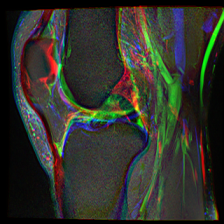

In [6]:
from IPython.display import display
from PIL import Image

role_to_preview = "SAG_FLUID"
role_idx = FIVE_ROLE_ORDER.index(role_to_preview)
valid_indices = np.flatnonzero(result.window_valid[role_idx])
if len(valid_indices) == 0:
    print(f"Không có window hợp lệ cho {role_to_preview}.")
else:
    window_idx = int(valid_indices[len(valid_indices) // 2])
    rgb_preview = np.transpose(result.images[role_idx, window_idx], (1, 2, 0))
    print(
        f"Preview: role={role_to_preview}, window={window_idx}, "
        f"slice positions={result.window_positions[role_idx, window_idx]:.4f}"
    )
    display(Image.fromarray(rgb_preview, mode="RGB"))

## 4. Save preprocessed tensors and diagnostics

File `.npz` này là cache đầu vào cho bước load/inference DINOv2 sau này. Nó không chứa labels và không phải model prediction.

In [7]:
tensor_path = OUTPUT_DIR / "dinov2_preprocessed_sample.npz"
diagnostics_path = OUTPUT_DIR / "dinov2_preprocessing_diagnostics.csv"
summary_path = OUTPUT_DIR / "dinov2_preprocessing_summary.json"

np.savez_compressed(
    tensor_path,
    images=result.images,
    window_valid=result.window_valid,
    window_positions=result.window_positions,
    role_order=np.asarray(FIVE_ROLE_ORDER),
    role_series_uids=np.asarray([result.role_series_uids[r] for r in FIVE_ROLE_ORDER]),
)
diagnostics_df.to_csv(diagnostics_path, index=False)

summary = {
    "study_instance_uid": result.study_uid,
    "source_notebook": "08_model_ensemble_kaggle_dataset_ready.ipynb",
    "source_sections": [12, 13, 14],
    "preprocessing": {
        "image_size": IMAGE_SIZE,
        "role_slices": N_ROLE_SLICES,
        "role_windows": N_ROLE_WINDOWS,
        "percentile_clip": [1.0, 99.5],
        "resize_interpolation": "cv2.INTER_AREA",
        "output_dtype": str(result.images.dtype),
        "normalization_applied_here": False,
    },
    "model_inputs": {
        "images_shape": list(result.images.shape),
        "window_valid_shape": list(result.window_valid.shape),
        "window_positions_shape": list(result.window_positions.shape),
        "valid_windows": result.n_valid_windows,
        "available_roles": result.n_available_roles,
    },
    "role_order": list(FIVE_ROLE_ORDER),
    "role_series_uids": result.role_series_uids,
    "diagnostics": result.diagnostics,
    "note": "No checkpoint loading or model inference has been performed.",
}
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved:", tensor_path)
print("Saved:", diagnostics_path)
print("Saved:", summary_path)

Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\dinov2_preprocessing\dinov2_preprocessed_sample.npz
Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\dinov2_preprocessing\dinov2_preprocessing_diagnostics.csv
Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\dinov2_preprocessing\dinov2_preprocessing_summary.json


## 5. Phase 2A completion criteria

- [ ] All 5 roles have status `ok`.
- [ ] `images` shape is `[5, 10, 3, 224, 224]`, dtype `uint8`.
- [ ] `window_valid` and `window_positions` are `[5, 10]`.
- [ ] All 50 windows are valid for this audited sample (expected for its 30–36 slices/series).
- [ ] Preview image looks like a coherent 3-slice stack, not empty/flat.
- [ ] Saved `.npz`, diagnostics CSV, and summary JSON.

**Scope boundary:** this notebook does not load the DINOv2 hub repo or fold checkpoints yet. Next step is to port/restore the exact five-role model class and test strict checkpoint loading.